sigma range used: [4.0, 60.0], 50 scales (geometric), threshold=0.05
675 blobs detected. Largest 5 circles (x, y, radius):
  centre=(112, 1), r=76.0px, sigma=53.7
  centre=(358, 4), r=68.0px, sigma=48.1
  centre=(241, 2), r=51.6px, sigma=36.5
  centre=(337, 47), r=48.8px, sigma=34.5
  centre=(110, 142), r=43.7px, sigma=30.9


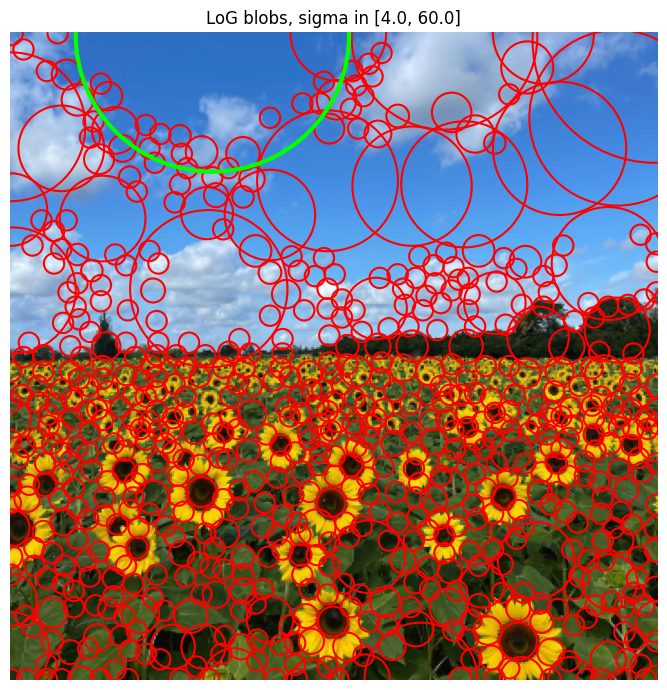

In [48]:
import cv2 as cv
import numpy as np
from scipy.ndimage import maximum_filter
import matplotlib.pyplot as plt

im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# scale space parameters
sigma_min, sigma_max, n_scales = 4.0, 60.0, 50
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)
threshold = 0.05   

#  build scale-space of scale-normalised LoG responses 
stack = []
for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    log = cv.Laplacian(g, cv.CV_32F, ksize=3)
    stack.append((s ** 2) * log)          # sigma^2 normalisation
stack = np.stack(stack, axis=0)          
resp = np.abs(stack)  

# 3D local maxima (x, y, sigma) 
local_max = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp > threshold)
si, ys, xs = np.nonzero(local_max)
blobs = [(x, y, sigmas[i] * np.sqrt(2), resp[i, y, x]) for i, y, x in zip(si, ys, xs)]  # r = sqrt(2)*sigma

#  simple non-maximum suppression of heavily overlapping circles 
blobs.sort(key=lambda b: -b[3])
kept = []
for b in blobs:
    ok = True
    for k in kept:
        d = np.hypot(b[0] - k[0], b[1] - k[1])
        if d < 0.7 * max(b[2], k[2]):     # centres too close blobs consider as same blob
            ok = False
            break
    if ok:
        kept.append(b)



kept_by_size = sorted(kept, key=lambda b: -b[2])
print(f"sigma range used: [{sigma_min}, {sigma_max}], {n_scales} scales (geometric), threshold={threshold}")
print(f"{len(kept)} blobs detected. Largest 5 circles (x, y, radius):")
for x, y, r, _ in kept_by_size[:5]:
    print(f"  centre=({x}, {y}), r={r:.1f}px, sigma={r / np.sqrt(2):.1f}")

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))      # BGR to RGB for matplotlib
for x, y, r, _ in kept:
    ax.add_patch(plt.Circle((x, y), r, color='r', fill=False, linewidth=1.5))
x, y, r, _ = kept_by_size[0]                       # highlight the largest
ax.add_patch(plt.Circle((x, y), r, color='lime', fill=False, linewidth=3))
ax.set_title(f'LoG blobs, sigma in [{sigma_min}, {sigma_max}]')
ax.axis('off')
plt.tight_layout()
plt.show()

In [49]:
from scipy.optimize import minimize

np.random.seed(0)  
#  data generation 
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

# line model
def line_from_two(p1, p2):
    d = p2 - p1
    nrm = np.array([-d[1], d[0]])
    nrm /= np.linalg.norm(nrm)            # ||[a,b]|| = 1
    return nrm[0], nrm[1], nrm @ p1       # a, b, d  with a x + b y = d

def line_err(params, P):
    a, b_, d = params
    return np.abs(P @ np.array([a, b_]) - d)   # normal distance 

def refine_line(P):
    """Total least squares with constraint a^2+b^2=1"""
    def cost(p):
        return np.sum((P @ p[:2] - p[2]) ** 2)
    # init from SVD (TLS closed form) for a good start
    c = P.mean(0)
    _, _, Vt = np.linalg.svd(P - c)
    nrm = Vt[-1]
    p0 = np.array([nrm[0], nrm[1], nrm @ c])
    cons = {'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1}
    res = minimize(cost, p0, constraints=cons, method='SLSQP')
    return res.x

def ransac_line(P, iters=1000, thresh=1.5, min_inliers=30):
    best, best_in, best_sample = None, np.zeros(len(P), bool), None
    for _ in range(iters):
        idx = np.random.choice(len(P), 2, replace=False)
        p = line_from_two(P[idx[0]], P[idx[1]])
        inl = line_err(p, P) < thresh
        if inl.sum() > best_in.sum() and inl.sum() >= min_inliers:
            best, best_in, best_sample = p, inl, idx
    return best, best_in, best_sample

#  circle model 
def circle_from_three(p1, p2, p3):
    A = np.array([[p2[0] - p1[0], p2[1] - p1[1]],
                  [p3[0] - p1[0], p3[1] - p1[1]]]) * 2
    if abs(np.linalg.det(A)) < 1e-6:
        return None                        # collinear
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

def circle_err(params, P):
    cx, cy, rr = params
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rr)   # radial error

def refine_circle(P, p0):
    cost = lambda p: np.sum((np.hypot(P[:, 0] - p[0], P[:, 1] - p[1]) - p[2]) ** 2)
    return minimize(cost, p0, method='Nelder-Mead').x

def ransac_circle(P, iters=2000, thresh=1.2, min_inliers=25):
    best, best_in, best_sample = None, np.zeros(len(P), bool), None
    for _ in range(iters):
        idx = np.random.choice(len(P), 3, replace=False)
        p = circle_from_three(*P[idx])
        if p is None:
            continue
        inl = circle_err(p, P) < thresh
        if inl.sum() > best_in.sum() and inl.sum() >= min_inliers:
            best, best_in, best_sample = p, inl, idx
    return best, best_in, best_sample


In [53]:
# prints each value to exactly 4 decimal places
def fmt(v):
    return "(" + ", ".join(f"{float(x):.4f}" for x in v) + ")"

RANSAC sample line (a,b,d): (-0.7005, -0.7137, -1.6374)  inliers: 56
Refined line (a,b,d): (0.7181, 0.6959, 1.5222)  ||[a,b]|| = 1.0000
RANSAC sample circle (cx,cy,r): (1.9171, 3.2473, 10.0129)  inliers: 43
Refined circle (cx,cy,r): (1.8695, 3.1251, 9.9303)   (ground truth: 2, 3, 10)


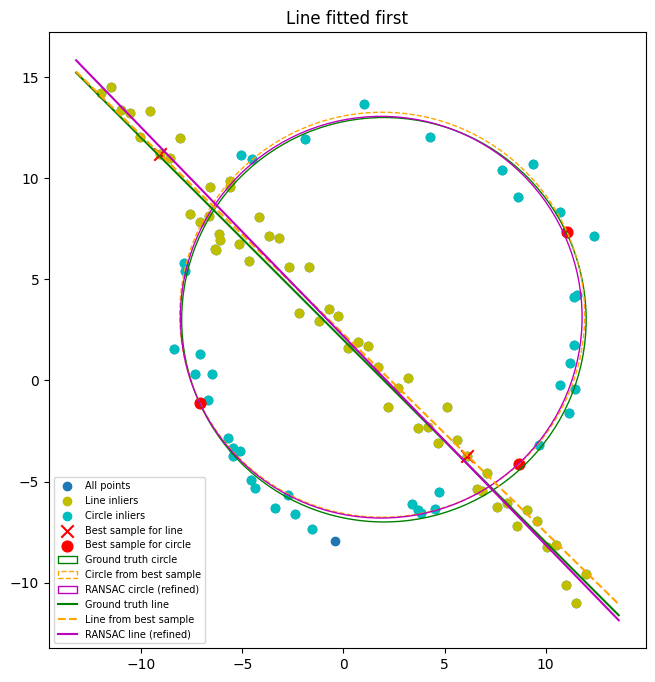

In [51]:
# fitting line first 
line_p, line_in, line_s = ransac_line(X)
line_ref = refine_line(X[line_in])
print("RANSAC sample line (a,b,d):", fmt(line_p), " inliers:", line_in.sum())
print("Refined line (a,b,d):", fmt(line_ref), f" ||[a,b]|| = {np.linalg.norm(line_ref[:2]):.4f}")

#  remove line consensus then fit circle 
rem = X[~line_in]
circ_p, circ_in, circ_s = ransac_circle(rem)
circ_ref = refine_circle(rem[circ_in], np.array(circ_p))
print("RANSAC sample circle (cx,cy,r):", fmt(circ_p), " inliers:", circ_in.sum())
print("Refined circle (cx,cy,r):", fmt(circ_ref), "  (ground truth: 2, 3, 10)")

#  plot 
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', label='All points')
ax.scatter(*X[line_in].T, c='y', label='Line inliers')
ax.scatter(*rem[circ_in].T, c='c', label='Circle inliers')
ax.scatter(*X[line_s].T, c='r', marker='x', s=80, label='Best sample for line')
ax.scatter(*rem[circ_s].T, c='r', s=60, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(circ_p[:2], circ_p[2], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle(circ_ref[:2], circ_ref[2], color='m', fill=False, label='RANSAC circle (refined)'))
xs = np.array(ax.get_xlim())
ax.plot(xs, m * xs + b, 'g', label='Ground truth line')
a_, b_, d_ = line_p
ax.plot(xs, (d_ - a_ * xs) / b_, 'orange', ls='--', label='Line from best sample')
a_, b_, d_ = line_ref
ax.plot(xs, (d_ - a_ * xs) / b_, 'm', label='RANSAC line (refined)')
ax.set_aspect('equal'); ax.legend(fontsize=7)
ax.set_title('Line fitted first')
plt.show()

Circle-first: RANSAC circle (cx,cy,r): (2.0162, 3.2398, 9.9743)  inliers: 58
Circle-first: refined circle (cx,cy,r): (1.9521, 3.0539, 9.9150)   (ground truth: 2, 3, 10)
Circle-first: RANSAC line (a,b,d): (-0.7147, -0.6994, -1.9487)  inliers: 41
Circle-first: refined line (a,b,d): (-0.7232, -0.6907, -1.6638)


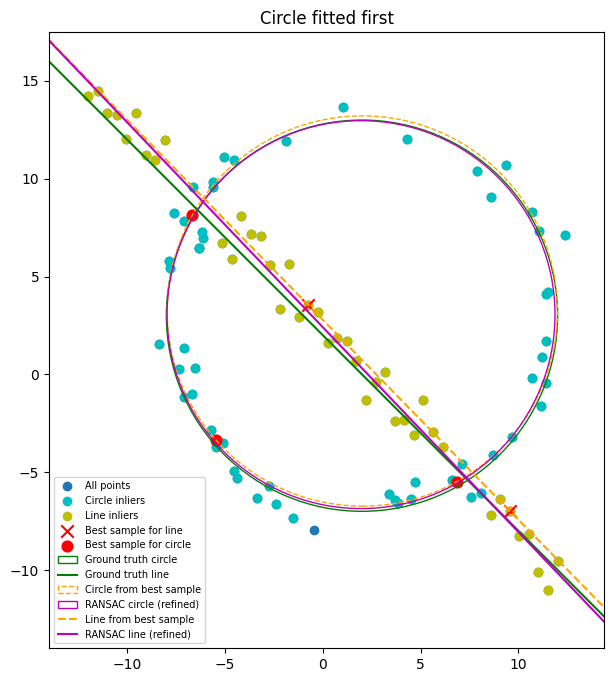

In [52]:
#  circle first 
circ1_p, circ1_in, circ1_s = ransac_circle(X, thresh=1.2, min_inliers=25)
circ1_ref = refine_circle(X[circ1_in], np.array(circ1_p))
print("Circle-first: RANSAC circle (cx,cy,r):", fmt(circ1_p), " inliers:", circ1_in.sum())
print("Circle-first: refined circle (cx,cy,r):", fmt(circ1_ref), "  (ground truth: 2, 3, 10)")

#  Remove the circle inliers and fit line
rem2 = X[~circ1_in]
line2_p, line2_in, line2_s = ransac_line(rem2, thresh=1.5, min_inliers=10)
if line2_p is None:
    print("Circle-first: no line with enough inliers was found in the remainder")
    line2_ref = None
else:
    line2_ref = refine_line(rem2[line2_in])
    print("Circle-first: RANSAC line (a,b,d):", fmt(line2_p), " inliers:", line2_in.sum())
    print("Circle-first: refined line (a,b,d):", fmt(line2_ref))

#  Plot
fig2, ax2 = plt.subplots(figsize=(8, 8))
ax2.scatter(*X.T, c='tab:blue', label='All points')
ax2.scatter(*X[circ1_in].T, c='c', label='Circle inliers')
if line2_p is not None:
    ax2.scatter(*rem2[line2_in].T, c='y', label='Line inliers')
    ax2.scatter(*rem2[line2_s].T, c='r', marker='x', s=80, label='Best sample for line')

ax2.scatter(*X[circ1_s].T, c='r', s=60, label='Best sample for circle')
ax2.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
xs = np.array([X[:, 0].min() - 2, X[:, 0].max() + 2])
ax2.plot(xs, m * xs + b, 'g', label='Ground truth line')
ax2.add_patch(plt.Circle(circ1_p[:2], circ1_p[2], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax2.add_patch(plt.Circle(circ1_ref[:2], circ1_ref[2], color='m', fill=False, label='RANSAC circle (refined)'))
if line2_ref is not None:
    a_, b_, d_ = line2_p
    ax2.plot(xs, (d_ - a_ * xs) / b_, 'orange', ls='--', label='Line from best sample')
    a_, b_, d_ = line2_ref
    ax2.plot(xs, (d_ - a_ * xs) / b_, 'm', label='RANSAC line (refined)')

ax2.set_xlim(xs); ax2.set_ylim(X[:, 1].min() - 3, X[:, 1].max() + 3)
ax2.set_aspect('equal'); ax2.set_title('Circle fitted first')
ax2.legend(fontsize=7)
plt.show()